<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Descriptive Statistics

_Author:_ Tim Book (is exceptionally uncool)

In this notebook we'll implement, review, and interpret various descriptive statistics including the mean, median, mode, variance, standard deviation, range, covariance and correlation.

In [1]:
# Imports... 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing the data

In [2]:
# In our data folder, and is named top10s_cleaned.csv.
df = pd.read_csv('data/top10s_cleaned.csv')
# Cesar Fernandez

In [3]:
df.head()

,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,Love The Way You Lie,Eminem,hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78


## Q: How many observations are there? How many variables?

In [4]:
df.shape
# Sunny Master
# We have 586 observations.
# We have 14 variables.

(586, 14)

In [5]:
df.dtypes
# The attribute .dtypes can help, but doesn't necessarily give us the answer!
# e.g. if there's a typo, we might get "object" when we shouldn't.
# e.g. if missing data exists!
# e.g. sometimes numbers don't mean numeric — e.g. ZIP code, phone numbers

title        object
artist       object
top genre    object
year          int64
bpm           int64
nrgy          int64
dnce          int64
dB            int64
live          int64
val           int64
dur           int64
acous         int64
spch          int64
pop           int64
dtype: object

## Q: Which variables are categorical, and which variables are quantitative? 

### Categorical:
* title
* artist
* top genre

### Quantitative:
* year
* bpm
* nrgy
* dnce
* dB
* live
* val
* dur
* acous
* spch
* pop

# Quantitative Statistics

## Mean

What's the mean danciness of these Top 10 songs?

Compute using `pandas`:

In [6]:
# Chris Sycamore
df.dnce.mean()

64.59044368600682

In [7]:
# Corey Duncan Jesmer
df['dnce'].mean()

64.59044368600682

Compute using `numpy`:

In [8]:
np.mean(df['dnce'])

64.59044368600682

Finally, "by hand" using other `numpy` functions:

## Median

In [9]:
df['dnce'].median()

66.0

## Skew
Plot the danciness metric. Would you describe this as skew or now? Does the mean vs median disagree?

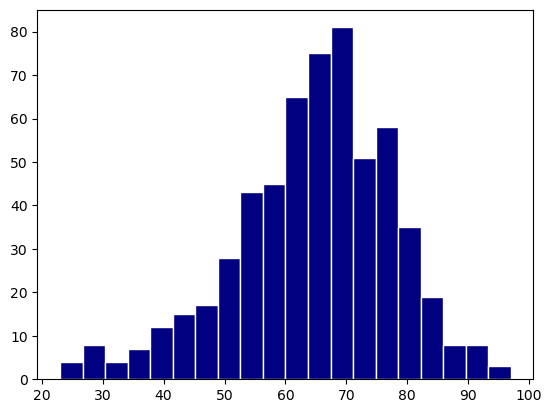

In [14]:
# Histogram. We only have one quantitative variable.

plt.hist(df['dnce'],
         bins=20, 
         color='navy',
         edgecolor='white');

# Sarah Roe, Sunny Master

Do the same mean vs median plotting for acousticity. What do you see?

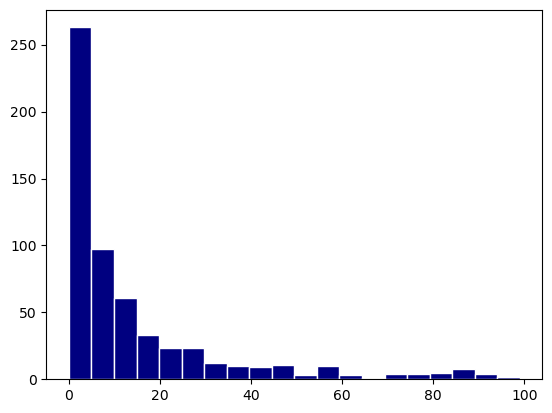

In [15]:
# Cesar Fernandez
plt.hist(df['acous'],
        bins=20,
        color="navy",
        edgecolor="white");

# What do I know about the mean and median of acousticity, without calculating this?
# This plot/data is right-skewed. (The tail extends to the right.)
# Mridul Sharma: The mean is larger than the median, because the mean is more sensitive to outliers.

## Variance & Standard Deviation

Let's compute the spread of the energy levels of the music. Let's compute their variances.

First, using `pandas`:

In [16]:
# Variance
df['nrgy'].var()
# Connor Finnerty: Pandas is using n-1 (sample)

256.7125463084508

Next, using `numpy`:

In [17]:
# Uh...
# Variance in NumPy
np.var(df['nrgy'])
# Connor Finnerty: NumPy is using N (population)

256.27447029085954

Finally, "by hand" using other `numpy` functions:

Ok, but what about the standard deviation?

In [18]:
# Pandas Standard Deviation
df['nrgy'].std()

16.022251599211977

In [20]:
# NumPy Standard Deviation
np.std(df['nrgy'], ddof=1)

# By default, NumPy will give us the population calculation.

16.022251599211977

## Five-number Summary

We can compute all of them pretty quickly with `.describe()`. Let's do that for the _speechiness_ of each song:

In [21]:
df['spch'].describe()

count    586.000000
mean       8.290102
std        7.301877
min        3.000000
25%        4.000000
50%        5.000000
75%        9.000000
max       48.000000
Name: spch, dtype: float64

## Boxplot
Does the above summary agree with a boxplot?

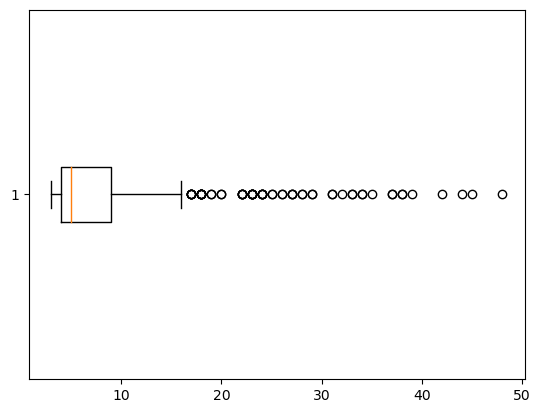

In [24]:
plt.boxplot(df['spch'], vert=False);

## Correlation
Let's take a look at the relationship between energy level and volume (dB).

First, let's plot them.

We can use `numpy` to compute the correlation coefficient, but it's in a weird format:

Turns out, statisticians love to look at **correlation matrices**, which is just a big grid of correlations. Notice the diagonal of 1. We can make this easier in `pandas`:

We can also use `seaborn`'s `heatmap()` function to make this a little nicer graphically.

In [ ]:
import seaborn as sns